In [1]:
# !pip install ta 

In [2]:
#impotrs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import seaborn as sns

import ta

# import yfinance as yf 

# Предобработка данных

In [3]:
df = pd.read_csv('AAPL.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

print("Форма:", df.shape)
print()
print(df.head())
print()
print(df.dtypes)

Форма: (10409, 7)

        Date      Open      High       Low     Close  Adj Close     Volume
0 1980-12-12  0.128348  0.128906  0.128348  0.128348   0.100323  469033600
1 1980-12-15  0.122210  0.122210  0.121652  0.121652   0.095089  175884800
2 1980-12-16  0.113281  0.113281  0.112723  0.112723   0.088110  105728000
3 1980-12-17  0.115513  0.116071  0.115513  0.115513   0.090291   86441600
4 1980-12-18  0.118862  0.119420  0.118862  0.118862   0.092908   73449600

Date         datetime64[ns]
Open                float64
High                float64
Low                 float64
Close               float64
Adj Close           float64
Volume                int64
dtype: object


In [4]:
# Дневная доходность
df['Return'] = df['Close'].pct_change()

# Логарифмическая доходность
df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1))

# Скользящие средние
df['SMA_10'] = df['Close'].rolling(window=10).mean()
df['SMA_20'] = df['Close'].rolling(window=20).mean()
df['SMA_50'] = df['Close'].rolling(window=50).mean()

# Экспоненциальное скользящее среднее
df['EMA_20'] = df['Close'].ewm(span=20, adjust=False).mean()

# Волатильность
df['Volatility_20'] = df['Return'].rolling(window=20).std()

# Расстояние цены от SMA_20
df['Close_vs_SMA20'] = (df['Close'] - df['SMA_20']) / df['SMA_20']

print(df[['Return', 'Log_Return', 'SMA_20', 'EMA_20', 'Volatility_20']].head(25))

      Return  Log_Return    SMA_20    EMA_20  Volatility_20
0        NaN         NaN       NaN  0.128348            NaN
1  -0.052171   -0.053581       NaN  0.127710            NaN
2  -0.073398   -0.076231       NaN  0.126283            NaN
3   0.024751    0.024450       NaN  0.125257            NaN
4   0.028992    0.028580       NaN  0.124648            NaN
5   0.061029    0.059239       NaN  0.124788            NaN
6   0.048669    0.047522       NaN  0.125499            NaN
7   0.042199    0.041333       NaN  0.126674            NaN
8   0.052628    0.051290       NaN  0.128428            NaN
9   0.092309    0.088294       NaN  0.131290            NaN
10  0.014084    0.013985       NaN  0.134092            NaN
11 -0.024304   -0.024604       NaN  0.136256            NaN
12 -0.028468   -0.028881       NaN  0.137788            NaN
13  0.010988    0.010928       NaN  0.139334            NaN
14 -0.021738   -0.021977       NaN  0.140413            NaN
15 -0.044448   -0.045466       NaN  0.14

In [5]:
# Добавляем День недели и месяц
df['Day_of_Week'] = df['Date'].dt.day_name()
df['Month'] = df['Date'].dt.month_name()

print(df[['Date', 'Day_of_Week', 'Month']].head(10))
print()
print(df['Day_of_Week'].value_counts())
print()
print(df['Month'].value_counts())

        Date Day_of_Week     Month
0 1980-12-12      Friday  December
1 1980-12-15      Monday  December
2 1980-12-16     Tuesday  December
3 1980-12-17   Wednesday  December
4 1980-12-18    Thursday  December
5 1980-12-19      Friday  December
6 1980-12-22      Monday  December
7 1980-12-23     Tuesday  December
8 1980-12-24   Wednesday  December
9 1980-12-26      Friday  December

Day_of_Week
Tuesday      2134
Wednesday    2133
Thursday     2094
Friday       2078
Monday       1970
Name: count, dtype: int64

Month
March        916
August       907
October      905
December     880
June         878
July         868
January      866
May          865
April        848
November     838
September    833
February     805
Name: count, dtype: int64


In [6]:
# Удаляем NaN
print("До очистки:", df.shape)
df = df.dropna().reset_index(drop=True)
print("После очистки:", df.shape)
# потеряли 49, переживем)))

До очистки: (10409, 17)
После очистки: (10360, 17)


In [7]:
# проверка
print("Форма:", df.shape)
print()
print("Столбцы:", df.columns.tolist())
print()
print("Пропусков:", df.isna().sum().sum())
print()
df.describe().round(3)

Форма: (10360, 17)

Столбцы: ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Return', 'Log_Return', 'SMA_10', 'SMA_20', 'SMA_50', 'EMA_20', 'Volatility_20', 'Close_vs_SMA20', 'Day_of_Week', 'Month']

Пропусков: 0



,Date,Open,High,Low,Close,Adj Close,Volume,Return,Log_Return,SMA_10,SMA_20,SMA_50,EMA_20,Volatility_20,Close_vs_SMA20
count,10360,10360.000,10360.000,10360.000,10360.000,10360.000,1.036000e+04,10360.000,10360.000,10360.000,10360.000,10360.000,10360.000,10360.000,10360.000
mean,2001-08-30 22:09:13.204633216,14.025,14.178,13.874,14.032,13.413,3.335353e+08,0.001,0.001,13.960,13.883,13.643,13.882,0.025,0.008
min,1981-02-24 00:00:00,0.050,0.050,0.049,0.049,0.038,0.000000e+00,-0.519,-0.731,0.053,0.056,0.058,0.056,0.005,-0.569
25%,1991-05-21 18:00:00,0.286,0.292,0.279,0.286,0.238,1.259524e+08,-0.013,-0.013,0.286,0.286,0.286,0.285,0.017,-0.031
50%,2001-08-21 12:00:00,0.473,0.482,0.464,0.475,0.391,2.216474e+08,0.000,0.000,0.472,0.468,0.464,0.465,0.023,0.009
75%,2011-12-07 06:00:00,14.325,14.489,14.163,14.354,12.327,4.144888e+08,0.015,0.015,14.321,14.126,14.013,14.208,0.031,0.048
max,2022-03-24 00:00:00,182.630,182.940,179.120,182.010,181.778,7.421641e+09,0.332,0.287,178.332,176.396,172.664,174.826,0.129,0.617
std,NaN,30.225,30.572,29.891,30.248,29.968,3.395278e+08,0.028,0.029,30.071,29.892,29.298,29.876,0.013,0.070


In [8]:
print("Датасет подготовлен:", df.shape)

Датасет подготовлен: (10360, 17)


In [9]:
df['Target'] = (df['Close'].shift(-1) > df['Close']).astype(int)
print(df['Target'].value_counts())

Target
0    5222
1    5138
Name: count, dtype: int64


In [10]:
df = df.dropna().reset_index(drop=True)
print("После финальной очистки:", df.shape)

После финальной очистки: (10360, 18)


In [11]:
# удаляем ложный таргет
df = df.iloc[:-1].reset_index(drop=True)
print("После удаления последней строки:", df.shape)

После удаления последней строки: (10359, 18)


In [12]:
# Добавляем признаки дат квартальных и годовых отчетов Apple
report_dates = pd.read_csv('report-dates.csv')

df['Date'] = pd.to_datetime(df['Date']).dt.date
report_dates['Filing date'] = pd.to_datetime(report_dates['Filing date']).dt.date

report_quarter_dates = set(report_dates['Filing date'])
report_year_dates = set(
    report_dates.loc[report_dates['Form type'].eq('10-K'), 'Filing date']
)

df['report_querter'] = df['Date'].isin(report_quarter_dates)
df['report_year'] = df['Date'].isin(report_year_dates)

df['Date'] = pd.to_datetime(df['Date']).dt.strftime('%Y-%m-%d')

print('report_querter=True:', df['report_querter'].sum())
print('report_year=True:', df['report_year'].sum())

df.to_csv('AAPL_features.csv', index=False)
print('Сохранено:', df.shape)
df.head()

report_querter=True: 114
report_year=True: 26
Сохранено: (10359, 20)


,Date,Open,High,Low,Close,Adj Close,Volume,Return,Log_Return,SMA_10,SMA_20,SMA_50,EMA_20,Volatility_20,Close_vs_SMA20,Day_of_Week,Month,Target,report_querter,report_year
0,1981-02-24,0.107143,0.107143,0.106027,0.106027,0.082876,16979200,-0.035531,-0.036177,0.114676,0.121763,0.132578,0.120632,0.033942,-0.129238,Tuesday,February,1,False,False
1,1981-02-25,0.112723,0.113281,0.112723,0.112723,0.088110,19488000,0.063154,0.061240,0.113783,0.120257,0.132266,0.119878,0.038141,-0.062647,Wednesday,February,1,False,False
2,1981-02-26,0.114397,0.114955,0.114397,0.114397,0.089418,10841600,0.014851,0.014741,0.113448,0.119057,0.132121,0.119356,0.038251,-0.039140,Thursday,February,1,False,False
3,1981-02-27,0.118304,0.119420,0.118304,0.118304,0.092472,14761600,0.034153,0.033583,0.113616,0.118304,0.132232,0.119256,0.038823,0.000004,Friday,February,1,False,False
4,1981-03-02,0.118862,0.119420,0.118862,0.118862,0.092908,11760000,0.004717,0.004706,0.114118,0.117941,0.132299,0.119219,0.037097,0.007810,Monday,March,0,False,False


## Постановка задачи регрессии следующего бара

Теперь решаем задачу multi-output regression: по информации на день `t` прогнозируем следующий дневной бар акции Apple (`AAPL`) на день `t+1`.

Целевые переменные:

- `Next_Open`
- `Next_High`
- `Next_Low`
- `Next_Close`

Это регрессия, потому что модель должна предсказать численные значения цен открытия, максимума, минимума и закрытия следующего бара. Старый бинарный `Target` для направления движения дальше не используем как признак и не используем как целевую переменную.

## Подготовка регрессионных таргетов

Загружаем финальный датасет `AAPL_features.csv`, сортируем его по дате и создаем таргеты следующего бара через `shift(-1)`. Последняя строка удаляется, потому что для нее неизвестен следующий бар.

При моделировании важно не использовать будущую информацию. Поэтому признаки берутся из строки текущего дня, а целевые значения — из следующего дня.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Загружаем финальный датасет, чтобы моделирующий раздел можно было запускать независимо
reg_df = pd.read_csv('AAPL_features.csv')
reg_df['Date'] = pd.to_datetime(reg_df['Date'])
reg_df = reg_df.sort_values('Date').reset_index(drop=True)

current_ohlc_cols = ['Open', 'High', 'Low', 'Close']
target_cols = ['Next_Open', 'Next_High', 'Next_Low', 'Next_Close']

for current_col, target_col in zip(current_ohlc_cols, target_cols):
    reg_df[target_col] = reg_df[current_col].shift(-1)

reg_df = reg_df.dropna(subset=target_cols).reset_index(drop=True)

print('Размер датасета для регрессии:', reg_df.shape)
print('Период:', reg_df['Date'].min().date(), '-', reg_df['Date'].max().date())
print('Количество пропусков:', reg_df.isna().sum().sum())

display(reg_df.head())
display(reg_df[target_cols].describe())

Размер датасета для регрессии: (10358, 24)
Период: 1981-02-24 - 2022-03-22
Количество пропусков: 0


,Date,Open,High,Low,Close,Adj Close,Volume,Return,Log_Return,SMA_10,...,Close_vs_SMA20,Day_of_Week,Month,Target,report_querter,report_year,Next_Open,Next_High,Next_Low,Next_Close
0,1981-02-24,0.107143,0.107143,0.106027,0.106027,0.082876,16979200,-0.035531,-0.036177,0.114676,...,-0.129238,Tuesday,February,1,False,False,0.112723,0.113281,0.112723,0.112723
1,1981-02-25,0.112723,0.113281,0.112723,0.112723,0.088110,19488000,0.063154,0.061240,0.113783,...,-0.062647,Wednesday,February,1,False,False,0.114397,0.114955,0.114397,0.114397
2,1981-02-26,0.114397,0.114955,0.114397,0.114397,0.089418,10841600,0.014851,0.014741,0.113448,...,-0.039140,Thursday,February,1,False,False,0.118304,0.119420,0.118304,0.118304
3,1981-02-27,0.118304,0.119420,0.118304,0.118304,0.092472,14761600,0.034153,0.033583,0.113616,...,0.000004,Friday,February,1,False,False,0.118862,0.119420,0.118862,0.118862
4,1981-03-02,0.118862,0.119420,0.118862,0.118862,0.092908,11760000,0.004717,0.004706,0.114118,...,0.007810,Monday,March,0,False,False,0.117746,0.117746,0.117188,0.117188


,Next_Open,Next_High,Next_Low,Next_Close
count,10358.000000,10358.000000,10358.000000,10358.000000
mean,14.011488,14.163964,13.860083,14.018080
std,30.188683,30.533986,29.853748,30.209694
min,0.049665,0.049665,0.049107,0.049107
25%,0.285714,0.292411,0.279018,0.285714
50%,0.473214,0.482143,0.464286,0.475133
75%,14.318572,14.479821,14.157678,14.339821
max,182.630005,182.940002,179.119995,182.009995


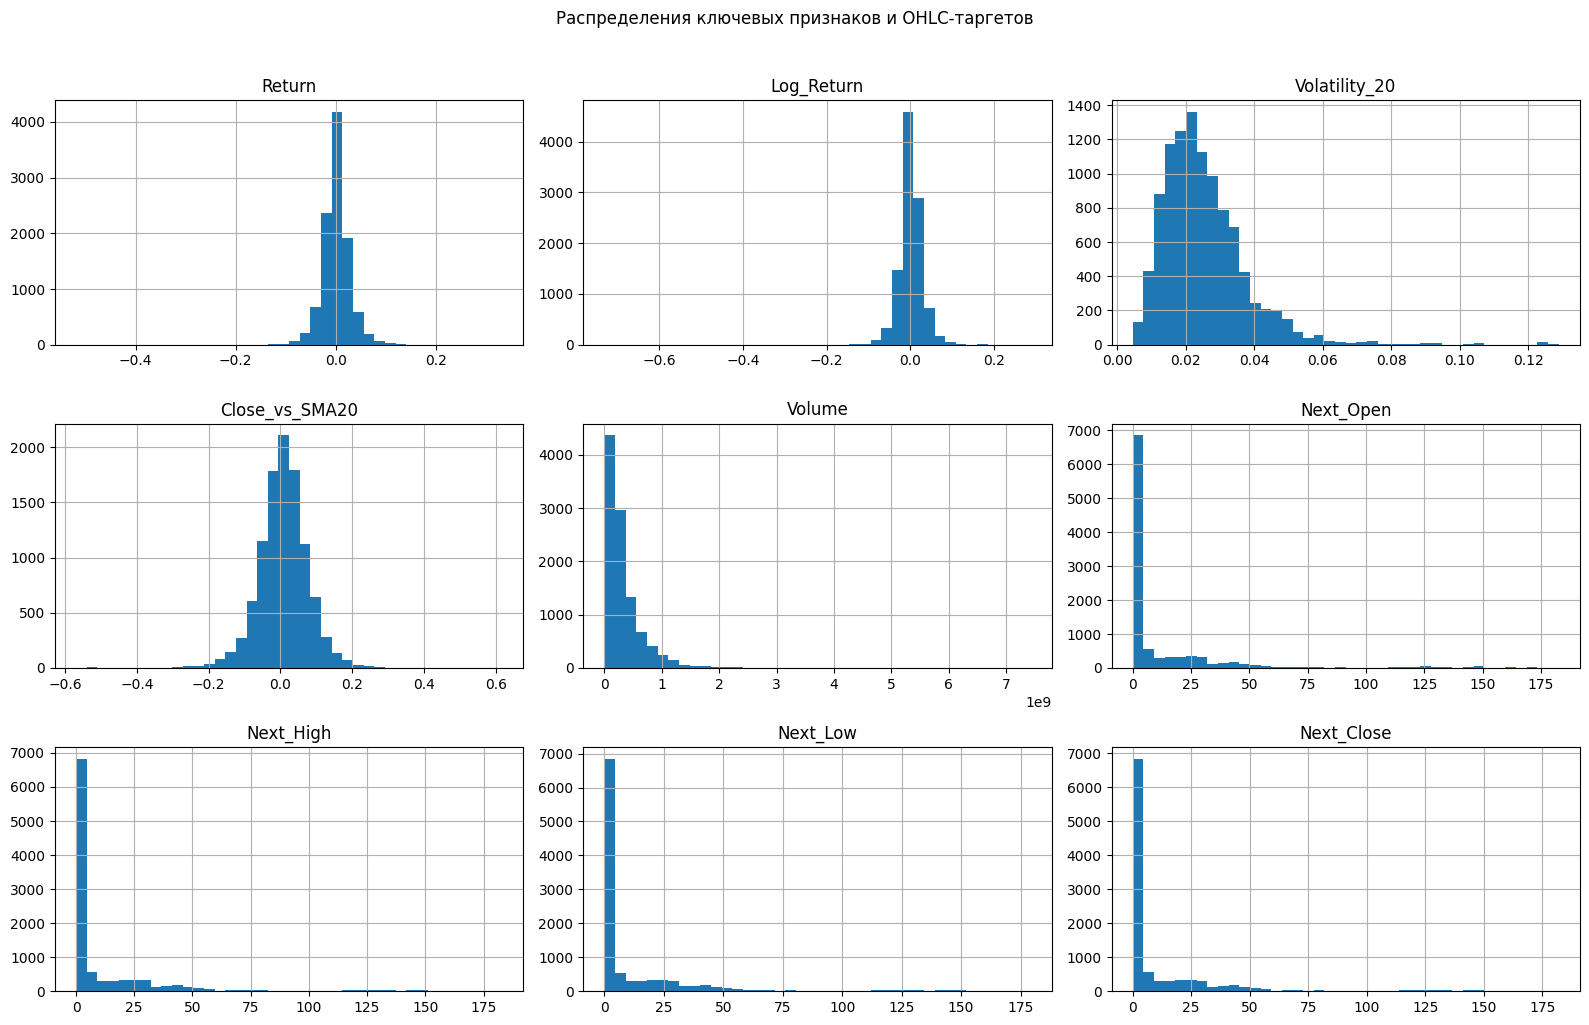

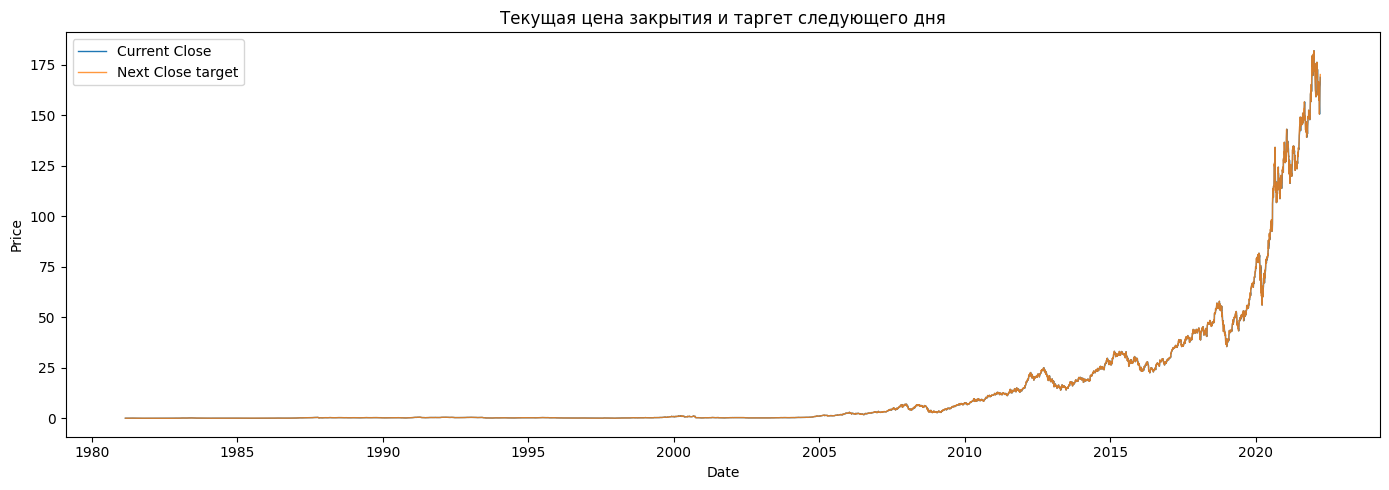

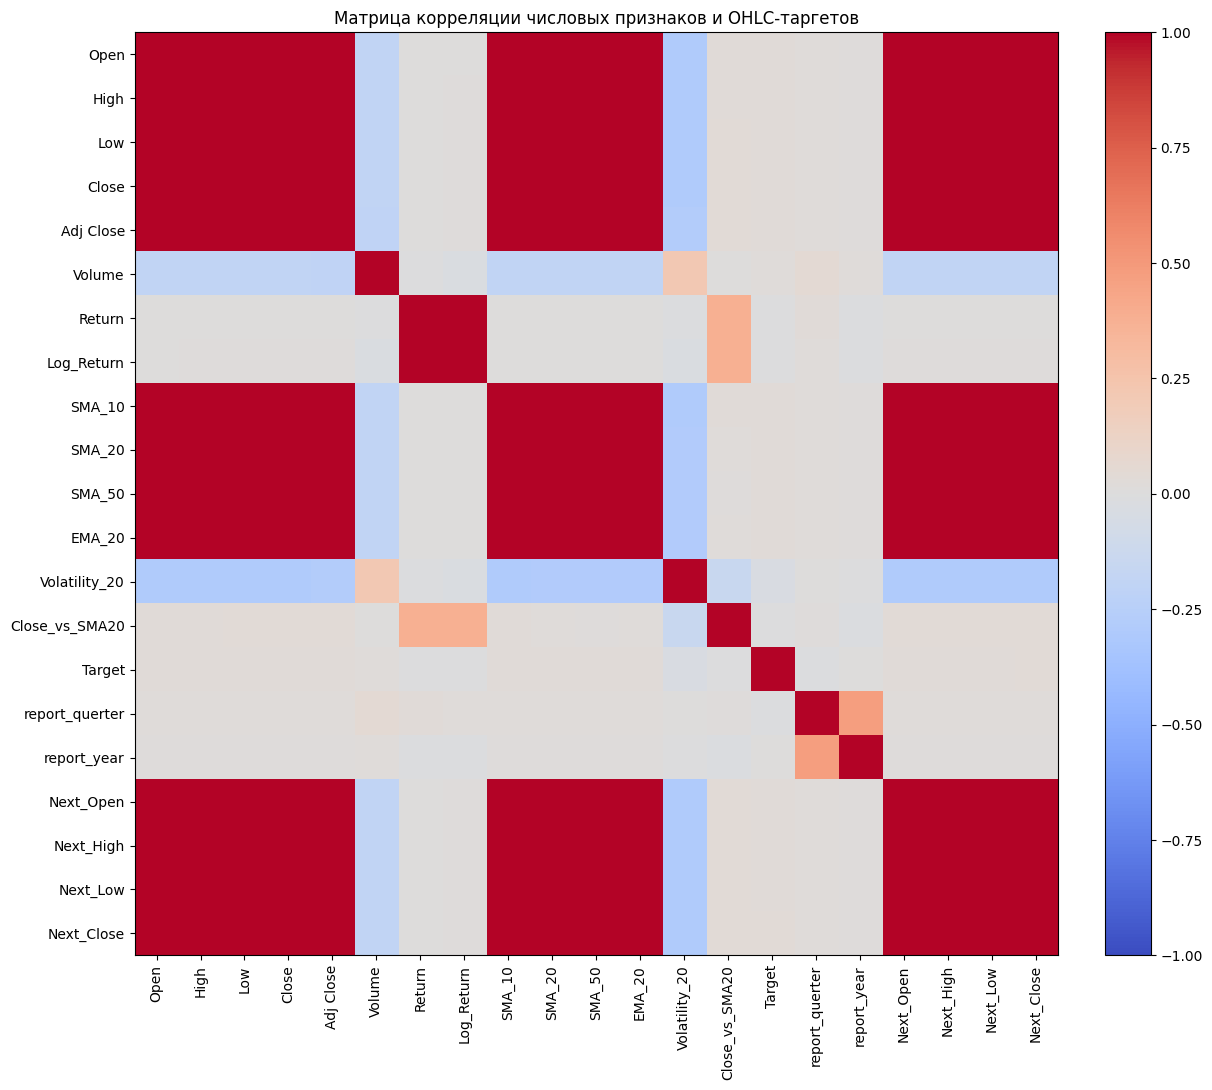

,Next_Open,Next_High,Next_Low,Next_Close
Close,0.999913,0.999880,0.999854,0.999782
Low,0.999843,0.999806,0.999814,0.999735
High,0.999838,0.999842,0.999754,0.999724
Open,0.999752,0.999745,0.999690,0.999639
Adj Close,0.999548,0.999541,0.999475,0.999426
SMA_10,0.999375,0.999399,0.999280,0.999279
EMA_20,0.999076,0.999119,0.998980,0.998993
SMA_20,0.998761,0.998816,0.998646,0.998676
SMA_50,0.997047,0.997120,0.996970,0.997009
Volatility_20,-0.290722,-0.289739,-0.291760,-0.290722


In [14]:
key_numeric_features = ['Return', 'Log_Return', 'Volatility_20', 'Close_vs_SMA20', 'Volume']

reg_df[key_numeric_features + target_cols].hist(bins=40, figsize=(16, 10))
plt.suptitle('Распределения ключевых признаков и OHLC-таргетов', y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plot_dates = reg_df['Date'].to_numpy()
plt.plot(plot_dates, reg_df['Close'].to_numpy(), label='Current Close', linewidth=1)
plt.plot(plot_dates, reg_df['Next_Close'].to_numpy(), label='Next Close target', linewidth=1, alpha=0.8)
plt.title('Текущая цена закрытия и таргет следующего дня')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()

numeric_columns = reg_df.select_dtypes(include=['number', 'bool']).columns
corr_matrix = reg_df[numeric_columns].corr()

plt.figure(figsize=(13, 11))
im = plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)
plt.title('Матрица корреляции числовых признаков и OHLC-таргетов')
plt.tight_layout()
plt.show()

display(corr_matrix[target_cols].drop(index=target_cols, errors='ignore').sort_values('Next_Close', key=lambda s: s.abs(), ascending=False).head(15))

Для регрессии следующего бара сильная корреляция между текущими ценами, скользящими средними и будущими OHLC-значениями ожидаема: рынок обычно меняется постепенно от дня к дню. При этом качество модели нельзя оценивать только по ошибке `Close`, потому что нам важен весь прогнозный бар: `Open`, `High`, `Low`, `Close`.

## Подготовка признаков и временное разделение

Для временного ряда нельзя случайно перемешивать наблюдения, иначе в обучение попадет информация из будущего. Поэтому делим выборку по времени: первые 80% наблюдений используем для обучения, последние 20% — для тестирования.

`Date`, старый бинарный `Target` и новые `Next_*`-таргеты исключаем из признаков. Категориальные признаки `Day_of_Week` и `Month` кодируем через one-hot encoding, числовые признаки масштабируем, а `report_querter` и `report_year` оставляем как бинарные индикаторы. Для TCN дополнительно формируем окна последних `lookback` торговых дней.

In [15]:
# Устанавливаем scikit-learn именно в текущий Jupyter kernel, если пакет недоступен
import sys
import subprocess
import importlib.util

if importlib.util.find_spec('sklearn') is None:
    print('scikit-learn не найден в текущем kernel. Устанавливаю...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'scikit-learn'])
    print('Готово. После установки перезапустите эту ячейку и продолжайте выполнение ноутбука.')
else:
    print('scikit-learn доступен в текущем kernel.')

scikit-learn доступен в текущем kernel.


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

feature_exclude_cols = ['Date'] + target_cols
if 'Target' in reg_df.columns:
    feature_exclude_cols.append('Target')

X_tabular = reg_df.drop(columns=feature_exclude_cols)
y_ohlc = reg_df[target_cols].copy()

categorical_features = ['Day_of_Week', 'Month']
binary_features = ['report_querter', 'report_year']
numeric_features = [
    col for col in X_tabular.columns
    if col not in categorical_features + binary_features
]

try:
    one_hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    one_hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)

feature_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', one_hot_encoder, categorical_features),
        ('bin', 'passthrough', binary_features),
    ],
    remainder='drop'
)

target_scaler = StandardScaler()

split_idx = int(len(reg_df) * 0.8)
X_train_tab = X_tabular.iloc[:split_idx]
X_test_tab = X_tabular.iloc[split_idx:]
y_train = y_ohlc.iloc[:split_idx]
y_test = y_ohlc.iloc[split_idx:]

X_train_scaled = feature_preprocessor.fit_transform(X_train_tab)
X_all_scaled = feature_preprocessor.transform(X_tabular)
y_train_scaled = target_scaler.fit_transform(y_train)
y_all_scaled = target_scaler.transform(y_ohlc)

# Небольшое окно снижает расход памяти и ускоряет TCN в локальном окружении.
lookback = 10


def make_windows(features, targets, lookback):
    X_windows, y_windows, row_indices = [], [], []
    features = np.asarray(features, dtype=np.float32)
    targets = np.asarray(targets, dtype=np.float32)
    for end_idx in range(lookback - 1, len(features)):
        start_idx = end_idx - lookback + 1
        X_windows.append(features[start_idx:end_idx + 1])
        y_windows.append(targets[end_idx])
        row_indices.append(end_idx)
    return (
        np.asarray(X_windows, dtype=np.float32),
        np.asarray(y_windows, dtype=np.float32),
        np.asarray(row_indices),
    )

X_seq_all, y_seq_all, seq_row_idx = make_windows(X_all_scaled, y_all_scaled, lookback)
train_seq_mask = seq_row_idx < split_idx
test_seq_mask = seq_row_idx >= split_idx

X_seq_train = X_seq_all[train_seq_mask]
y_seq_train = y_seq_all[train_seq_mask]
X_seq_test = X_seq_all[test_seq_mask]
y_seq_test_scaled = y_seq_all[test_seq_mask]
y_seq_test = target_scaler.inverse_transform(y_seq_test_scaled)
seq_test_dates = reg_df['Date'].iloc[seq_row_idx[test_seq_mask]].reset_index(drop=True)

# Для локального запуска ограничиваем TCN последними окнами train-части.
# Это сохраняет временную логику и не перегружает TensorFlow.
max_train_windows = 2500
X_seq_train_fit = X_seq_train[-max_train_windows:]
y_seq_train_fit = y_seq_train[-max_train_windows:]
val_size = max(1, int(len(X_seq_train_fit) * 0.2))
X_tcn_train = X_seq_train_fit[:-val_size]
y_tcn_train = y_seq_train_fit[:-val_size]
X_tcn_val = X_seq_train_fit[-val_size:]
y_tcn_val = y_seq_train_fit[-val_size:]

print('Train period:', reg_df['Date'].iloc[0].date(), '-', reg_df['Date'].iloc[split_idx - 1].date())
print('Test period:', reg_df['Date'].iloc[split_idx].date(), '-', reg_df['Date'].iloc[-1].date())
print('Tabular train:', X_train_tab.shape)
print('Tabular test:', X_test_tab.shape)
print('TCN train windows:', X_seq_train.shape)
print('TCN test windows:', X_seq_test.shape)
print('Number of transformed features:', X_all_scaled.shape[1])

Train period: 1981-02-24 - 2013-12-27
Test period: 2013-12-30 - 2022-03-22
Tabular train: (8286, 18)
Tabular test: (2072, 18)
TCN train windows: (8277, 10, 33)
TCN test windows: (2072, 10, 33)
Number of transformed features: 33


## Метрики качества прогноза бара

Для оценки используем классические регрессионные метрики и метрики пересечения прогнозного бара с реальным. Реальный и прогнозный бары рассматриваем как ценовые интервалы `[Low, High]`. Чем больше пересечение этих интервалов, тем лучше модель попала в диапазон следующего дня.

Классический `mAP` из object detection требует confidence score и ранжирования объектов. Здесь используем адаптированный `mAP-like`: среднюю долю прогнозов, где `IoU` выше набора порогов от `0.50` до `0.95`.

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error


def postprocess_ohlc(pred):
    """Исправляет прогноз так, чтобы High был максимумом бара, а Low минимумом."""
    pred = np.asarray(pred).copy()
    open_pred = pred[:, 0]
    close_pred = pred[:, 3]
    high_pred = np.max(pred, axis=1)
    low_pred = np.min(pred, axis=1)
    return np.column_stack([open_pred, high_pred, low_pred, close_pred])


def bar_iou(y_true, y_pred):
    true_low = y_true[:, 2]
    true_high = y_true[:, 1]
    pred_low = y_pred[:, 2]
    pred_high = y_pred[:, 1]

    intersection = np.maximum(0, np.minimum(true_high, pred_high) - np.maximum(true_low, pred_low))
    union = np.maximum(true_high, pred_high) - np.minimum(true_low, pred_low)
    return np.divide(intersection, union, out=np.zeros_like(intersection, dtype=float), where=union > 0)


def smape(y_true, y_pred):
    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2
    return np.mean(np.divide(np.abs(y_true - y_pred), denominator, out=np.zeros_like(y_true, dtype=float), where=denominator != 0)) * 100


def evaluate_ohlc_forecast(model_name, y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = postprocess_ohlc(y_pred)
    iou_values = bar_iou(y_true, y_pred)
    thresholds = np.arange(0.50, 1.00, 0.05)

    result = {
        'model': model_name,
        'MAE_mean': mean_absolute_error(y_true, y_pred),
        'RMSE_mean': np.sqrt(mean_squared_error(y_true, y_pred)),
        'sMAPE_mean_%': smape(y_true, y_pred),
        'Bar_IoU_mean': iou_values.mean(),
        'IoU@0.50': (iou_values >= 0.50).mean(),
        'IoU@0.70': (iou_values >= 0.70).mean(),
        'IoU@0.90': (iou_values >= 0.90).mean(),
        'mAP_like_0.50_0.95': np.mean([(iou_values >= threshold).mean() for threshold in thresholds]),
    }

    for idx, col in enumerate(target_cols):
        result[f'MAE_{col}'] = mean_absolute_error(y_true[:, idx], y_pred[:, idx])
        result[f'RMSE_{col}'] = np.sqrt(mean_squared_error(y_true[:, idx], y_pred[:, idx]))

    return result, y_pred, iou_values

## Baseline и классические регрессионные модели

Перед TCN сравним несколько простых решений. Наивный baseline прогнозирует следующий бар равным текущему бару. Это сильный baseline для ценовых рядов, потому что дневные цены обычно меняются плавно. Затем обучим Ridge-регрессию и Random Forest для multi-output прогноза `Open`, `High`, `Low`, `Close`.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

regression_results = []
predictions_by_model = {}
iou_by_model = {}

# Сравниваем модели на одной и той же test-части после split_idx.
y_test_values = y_test.values

naive_pred = X_test_tab[current_ohlc_cols].values
naive_result, naive_pred_processed, naive_iou = evaluate_ohlc_forecast('Naive current OHLC', y_test_values, naive_pred)
regression_results.append(naive_result)
predictions_by_model['Naive current OHLC'] = naive_pred_processed
iou_by_model['Naive current OHLC'] = naive_iou

ridge_model = Pipeline(steps=[
    ('preprocessor', feature_preprocessor),
    ('model', Ridge(alpha=1.0)),
])
ridge_model.fit(X_train_tab, y_train)
ridge_pred = ridge_model.predict(X_test_tab)
ridge_result, ridge_pred_processed, ridge_iou = evaluate_ohlc_forecast('Ridge Regression', y_test_values, ridge_pred)
regression_results.append(ridge_result)
predictions_by_model['Ridge Regression'] = ridge_pred_processed
iou_by_model['Ridge Regression'] = ridge_iou

rf_model = Pipeline(steps=[
    ('preprocessor', feature_preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    )),
])
rf_model.fit(X_train_tab, y_train)
rf_pred = rf_model.predict(X_test_tab)
rf_result, rf_pred_processed, rf_iou = evaluate_ohlc_forecast('Random Forest Regressor', y_test_values, rf_pred)
regression_results.append(rf_result)
predictions_by_model['Random Forest Regressor'] = rf_pred_processed
iou_by_model['Random Forest Regressor'] = rf_iou

metrics_df = pd.DataFrame(regression_results).sort_values('MAE_mean').reset_index(drop=True)
display(metrics_df)

,model,MAE_mean,RMSE_mean,sMAPE_mean_%,Bar_IoU_mean,IoU@0.50,IoU@0.70,IoU@0.90,mAP_like_0.50_0.95,MAE_Next_Open,RMSE_Next_Open,MAE_Next_High,RMSE_Next_High,MAE_Next_Low,RMSE_Next_Low,MAE_Next_Close,RMSE_Next_Close
0,Naive current OHLC,0.752775,1.344881,1.170919,0.369315,0.326255,0.118243,0.008687,0.123890,0.818528,1.487001,0.668706,1.203540,0.733921,1.273983,0.789944,1.397178
1,Ridge Regression,1.623804,2.500747,2.259667,0.107593,0.083012,0.028475,0.002896,0.030985,1.646382,2.457119,1.480185,2.196620,1.868298,2.888128,1.500350,2.410618
2,Random Forest Regressor,35.165759,55.447879,59.468057,0.038768,0.030405,0.008687,0.000965,0.010956,35.126467,55.409691,35.628805,56.151228,34.692336,54.726232,35.215426,55.495174


## TCN: Temporal Convolutional Network

TCN работает не с одной строкой, а с окном последних `lookback` дней. Внутри используются causal dilated convolutions: модель видит только прошлые значения и постепенно расширяет receptive field за счет dilation rates. На выходе получаем четыре числа: прогноз `Next_Open`, `Next_High`, `Next_Low`, `Next_Close`.

In [19]:
import gc
import importlib.util

tensorflow_available = importlib.util.find_spec('tensorflow') is not None

if not tensorflow_available:
    print('TensorFlow не установлен в текущем Jupyter kernel.')
    print('TCN не будет обучена в этом запуске, но baseline-модели выше уже можно оценивать.')
    print('Чтобы запустить TCN, переключите kernel на Python 3.8, где TensorFlow доступен, или установите TensorFlow в совместимое окружение.')
    metrics_df = pd.DataFrame(regression_results).sort_values('MAE_mean').reset_index(drop=True)
    display(metrics_df)
else:
    import tensorflow as tf
    from tensorflow.keras import layers, models, callbacks

    tf.keras.backend.clear_session()
    gc.collect()

    try:
        # Ограничиваем число потоков, чтобы TensorFlow не подвешивал локальное окружение.
        tf.config.threading.set_intra_op_parallelism_threads(2)
        tf.config.threading.set_inter_op_parallelism_threads(2)
    except RuntimeError:
        print('Потоки TensorFlow уже инициализированы. Если обучение зависает, сделайте Restart Kernel и запустите ноутбук заново.')

    tf.random.set_seed(42)
    np.random.seed(42)

    def residual_tcn_block(x, filters, kernel_size, dilation_rate, dropout_rate):
        shortcut = x

        x = layers.Conv1D(
            filters=filters,
            kernel_size=kernel_size,
            padding='causal',
            dilation_rate=dilation_rate,
            activation='relu',
        )(x)
        x = layers.LayerNormalization()(x)
        x = layers.Dropout(dropout_rate)(x)

        x = layers.Conv1D(
            filters=filters,
            kernel_size=kernel_size,
            padding='causal',
            dilation_rate=dilation_rate,
            activation='relu',
        )(x)
        x = layers.LayerNormalization()(x)

        if shortcut.shape[-1] != filters:
            shortcut = layers.Conv1D(filters=filters, kernel_size=1, padding='same')(shortcut)

        x = layers.Add()([shortcut, x])
        return layers.Activation('relu')(x)

    def build_tcn_model(input_shape, output_dim=4):
        inputs = layers.Input(shape=input_shape)
        x = inputs

        for dilation_rate in [1, 2]:
            x = residual_tcn_block(
                x,
                filters=16,
                kernel_size=3,
                dilation_rate=dilation_rate,
                dropout_rate=0.15,
            )

        x = layers.Lambda(lambda tensor: tensor[:, -1, :])(x)
        x = layers.Dense(16, activation='relu')(x)
        x = layers.Dropout(0.15)(x)
        outputs = layers.Dense(output_dim)(x)

        model = models.Model(inputs=inputs, outputs=outputs)
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
            loss=tf.keras.losses.Huber(),
            metrics=['mae'],
        )
        return model

    tcn_model = build_tcn_model(input_shape=(X_tcn_train.shape[1], X_tcn_train.shape[2]))
    print('TCN parameters:', tcn_model.count_params())

    early_stopping = callbacks.EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True,
    )

    history = tcn_model.fit(
        X_tcn_train,
        y_tcn_train,
        epochs=8,
        batch_size=8,
        validation_data=(X_tcn_val, y_tcn_val),
        shuffle=False,
        callbacks=[early_stopping],
        verbose=1,
    )

    tcn_pred_scaled = tcn_model.predict(X_seq_test)
    tcn_pred = target_scaler.inverse_transform(tcn_pred_scaled)
    tcn_result, tcn_pred_processed, tcn_iou = evaluate_ohlc_forecast('TCN', y_seq_test, tcn_pred)

    regression_results.append(tcn_result)
    predictions_by_model['TCN'] = tcn_pred_processed
    iou_by_model['TCN'] = tcn_iou

    metrics_df = pd.DataFrame(regression_results).sort_values('MAE_mean').reset_index(drop=True)
    display(metrics_df)

TCN parameters: 4964
Epoch 1/8
250/250 [==============================] - 2s 3ms/step - loss: 0.1478 - mae: 0.4102 - val_loss: 0.4721 - val_mae: 0.8988
Epoch 2/8
250/250 [==============================] - 0s 2ms/step - loss: 0.0812 - mae: 0.2794 - val_loss: 0.3619 - val_mae: 0.7616
Epoch 3/8
250/250 [==============================] - 0s 2ms/step - loss: 0.0518 - mae: 0.2319 - val_loss: 0.2967 - val_mae: 0.6846
Epoch 4/8
250/250 [==============================] - 0s 2ms/step - loss: 0.0366 - mae: 0.1927 - val_loss: 0.2096 - val_mae: 0.5525
Epoch 5/8
250/250 [==============================] - 0s 2ms/step - loss: 0.0321 - mae: 0.1778 - val_loss: 0.2186 - val_mae: 0.5748
Epoch 6/8
250/250 [==============================] - 0s 2ms/step - loss: 0.0288 - mae: 0.1612 - val_loss: 0.1867 - val_mae: 0.5216
Epoch 7/8
250/250 [==============================] - 0s 2ms/step - loss: 0.0284 - mae: 0.1601 - val_loss: 0.1947 - val_mae: 0.5466
Epoch 8/8
250/250 [==============================] - 1s 2ms/st

,model,MAE_mean,RMSE_mean,sMAPE_mean_%,Bar_IoU_mean,IoU@0.50,IoU@0.70,IoU@0.90,mAP_like_0.50_0.95,MAE_Next_Open,RMSE_Next_Open,MAE_Next_High,RMSE_Next_High,MAE_Next_Low,RMSE_Next_Low,MAE_Next_Close,RMSE_Next_Close
0,Naive current OHLC,0.752775,1.344881,1.170919,0.369315,0.326255,0.118243,0.008687,0.123890,0.818528,1.487001,0.668706,1.203540,0.733921,1.273983,0.789944,1.397178
1,Ridge Regression,1.623804,2.500747,2.259667,0.107593,0.083012,0.028475,0.002896,0.030985,1.646382,2.457119,1.480185,2.196620,1.868298,2.888128,1.500350,2.410618
2,TCN,27.078226,37.634941,49.106956,0.000000,0.000000,0.000000,0.000000,0.000000,26.496626,36.488731,23.620913,32.304794,28.795450,40.130512,29.399916,40.988644
3,Random Forest Regressor,35.165759,55.447879,59.468057,0.038768,0.030405,0.008687,0.000965,0.010956,35.126467,55.409691,35.628805,56.151228,34.692336,54.726232,35.215426,55.495174


## Визуализация качества прогноза

Сравним модели по таблице метрик и визуально посмотрим, как лучшая модель прогнозирует `Close` и ценовой диапазон `[Low, High]`. Дополнительно построим распределение `IoU`, чтобы увидеть, насколько часто прогнозный бар пересекается с реальным.

Лучшая модель по среднему MAE: Naive current OHLC


,model,MAE_mean,RMSE_mean,sMAPE_mean_%,Bar_IoU_mean,IoU@0.50,IoU@0.70,IoU@0.90,mAP_like_0.50_0.95,MAE_Next_Open,RMSE_Next_Open,MAE_Next_High,RMSE_Next_High,MAE_Next_Low,RMSE_Next_Low,MAE_Next_Close,RMSE_Next_Close
0,Naive current OHLC,0.752775,1.344881,1.170919,0.369315,0.326255,0.118243,0.008687,0.123890,0.818528,1.487001,0.668706,1.203540,0.733921,1.273983,0.789944,1.397178
1,Ridge Regression,1.623804,2.500747,2.259667,0.107593,0.083012,0.028475,0.002896,0.030985,1.646382,2.457119,1.480185,2.196620,1.868298,2.888128,1.500350,2.410618
2,TCN,27.078226,37.634941,49.106956,0.000000,0.000000,0.000000,0.000000,0.000000,26.496626,36.488731,23.620913,32.304794,28.795450,40.130512,29.399916,40.988644
3,Random Forest Regressor,35.165759,55.447879,59.468057,0.038768,0.030405,0.008687,0.000965,0.010956,35.126467,55.409691,35.628805,56.151228,34.692336,54.726232,35.215426,55.495174


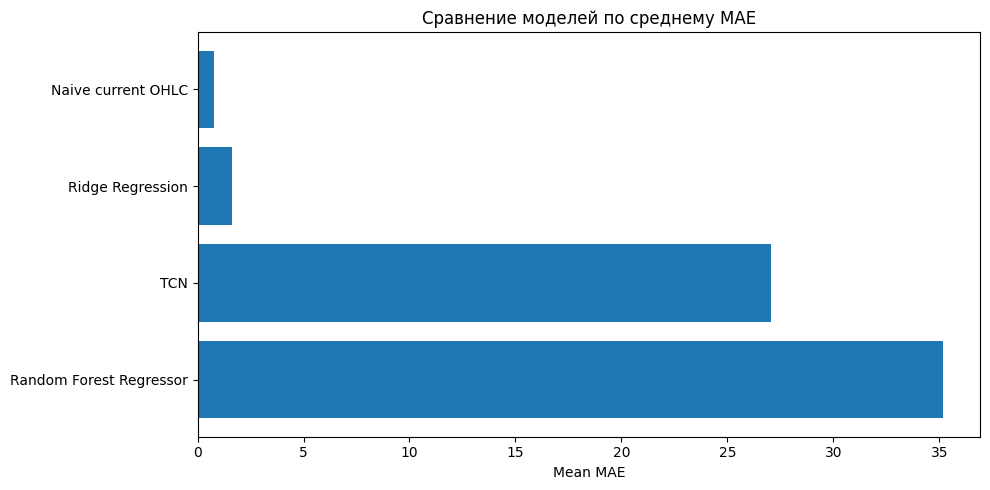

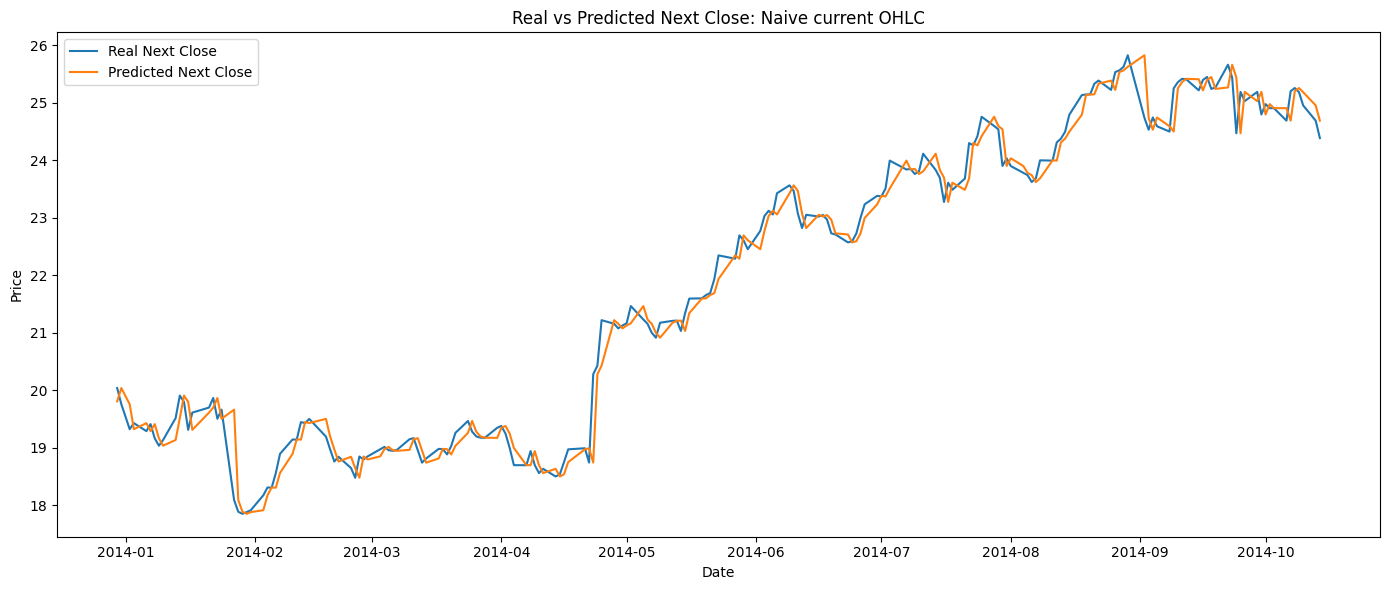

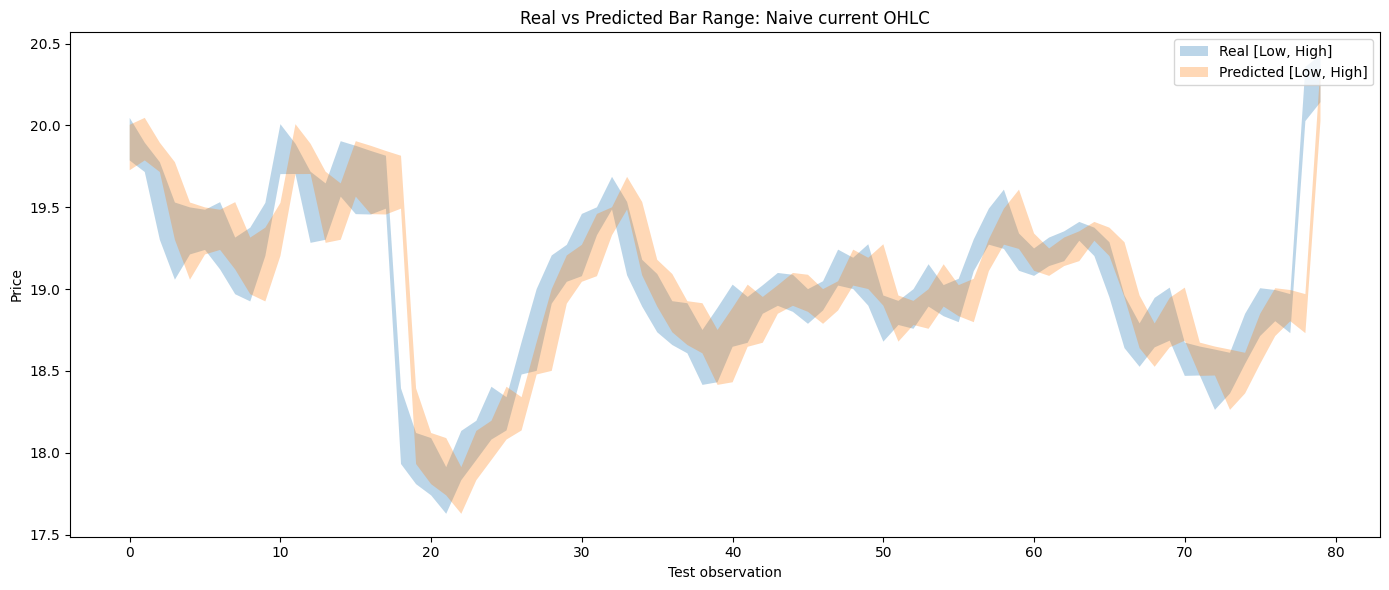

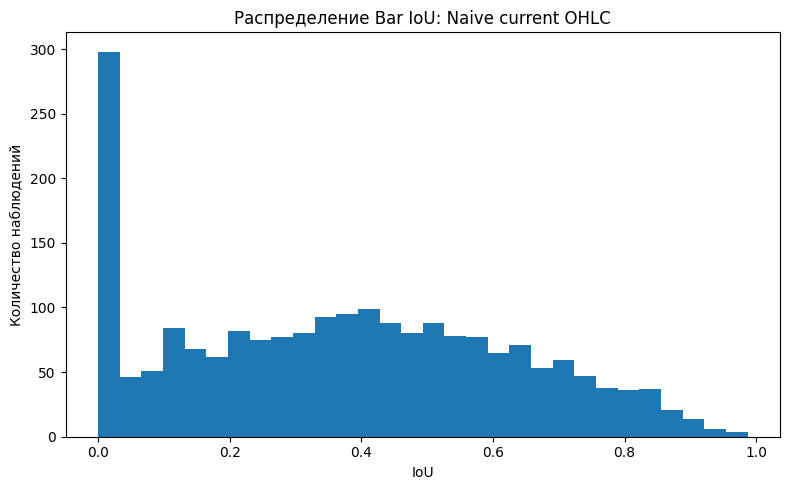

In [20]:
best_regression_model = metrics_df.iloc[0]['model']
best_prediction = predictions_by_model[best_regression_model]
best_iou = iou_by_model[best_regression_model]

print('Лучшая модель по среднему MAE:', best_regression_model)
display(metrics_df)

plt.figure(figsize=(10, 5))
plt.barh(metrics_df['model'], metrics_df['MAE_mean'])
plt.xlabel('Mean MAE')
plt.title('Сравнение моделей по среднему MAE')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Для TCN тестовый y может начинаться с той же test-части, но используем корректные массивы по выбранной модели.
if best_regression_model == 'TCN':
    plot_dates = seq_test_dates
    y_true_plot = y_seq_test
else:
    plot_dates = reg_df['Date'].iloc[split_idx:].reset_index(drop=True)
    y_true_plot = y_test_values

plot_len = min(200, len(plot_dates))

plt.figure(figsize=(14, 6))
plot_dates_np = plot_dates.iloc[:plot_len].to_numpy()
plt.plot(plot_dates_np, y_true_plot[:plot_len, 3], label='Real Next Close', linewidth=1.5)
plt.plot(plot_dates_np, best_prediction[:plot_len, 3], label='Predicted Next Close', linewidth=1.5)
plt.title(f'Real vs Predicted Next Close: {best_regression_model}')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()

interval_len = min(80, len(plot_dates))
x_axis = np.arange(interval_len)

plt.figure(figsize=(14, 6))
plt.fill_between(
    x_axis,
    y_true_plot[:interval_len, 2],
    y_true_plot[:interval_len, 1],
    alpha=0.3,
    label='Real [Low, High]',
)
plt.fill_between(
    x_axis,
    best_prediction[:interval_len, 2],
    best_prediction[:interval_len, 1],
    alpha=0.3,
    label='Predicted [Low, High]',
)
plt.title(f'Real vs Predicted Bar Range: {best_regression_model}')
plt.xlabel('Test observation')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(best_iou, bins=30)
plt.title(f'Распределение Bar IoU: {best_regression_model}')
plt.xlabel('IoU')
plt.ylabel('Количество наблюдений')
plt.tight_layout()
plt.show()

## Итоговые выводы

В проекте задача была переформулирована как регрессия следующего OHLC-бара акции Apple. Модель прогнозирует сразу четыре значения: `Open`, `High`, `Low`, `Close` следующего торгового дня.

Для оценки качества используются не только стандартные регрессионные метрики `MAE`, `RMSE` и `sMAPE`, но и метрики пересечения прогнозного бара с реальным: средний `Bar IoU`, `IoU@0.50`, `IoU@0.70`, `IoU@0.90` и `mAP-like` по набору IoU-порогов. Это лучше соответствует идее сравнения прогнозного и фактического бара.

В качестве моделей сравниваются наивный прогноз текущим баром, классические регрессионные модели и нейросетевая TCN. При интерпретации результатов важно учитывать, что даже хороший прогноз бара не является готовой торговой стратегией: здесь не учитываются комиссии, спреды, проскальзывание, ликвидность, новости и изменение рыночного режима.